# Understanding NumPy ndarrays

<b>Functions and attributes:</b> .tolist(), from skimage import data, plt.imshow(), .strides

In [1]:
import numpy as np

### Making ndarrays

In [2]:
# Manually creating a 3-D list
three_dim_list = [[[1, 2], [3, 4]], [[5, 6], [7, 8]]]

# Convert into a 3-D matrix
three_dim_array = np.array(three_dim_list)
print(three_dim_array)

# Can convert back to list
back_to_a_list = three_dim_array.tolist()

[[[1 2]
  [3 4]]

 [[5 6]
  [7 8]]]


In [3]:
# Indexing [matrix, row, column]
three_dim_array[1, 0, 1] = 99

three_dim_array.shape

(2, 2, 2)

In [4]:
# Making a 4-D matrix
four_dim_array = np.zeros((3, 3, 2, 2))
four_dim_array

array([[[[0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.]]],


       [[[0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.]]],


       [[[0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.]],

        [[0., 0.],
         [0., 0.]]]])

### Slicing and aggregating

In [5]:
# Make an array of random integers (4 x 3 x 3 = 36)
rng = np.random.default_rng()
array = rng.integers(0, 10, size=36).reshape(4, 3, 3)
array

array([[[6, 4, 4],
        [6, 1, 2],
        [8, 3, 3]],

       [[9, 5, 4],
        [9, 6, 7],
        [2, 5, 2]],

       [[8, 3, 1],
        [3, 1, 6],
        [9, 7, 5]],

       [[7, 2, 5],
        [0, 1, 8],
        [6, 9, 3]]])

In [6]:
# Slicing[third matrix (index 2), all rows (:), first and third column (::2)]
# alternatively [2, :, [0, 2]]
array[2, :, ::2]

array([[8, 1],
       [3, 6],
       [9, 5]])

In [7]:
# Boolean indexing
# for each element >= 8, make it 30
array[array >= 8] = 30
array

array([[[ 6,  4,  4],
        [ 6,  1,  2],
        [30,  3,  3]],

       [[30,  5,  4],
        [30,  6,  7],
        [ 2,  5,  2]],

       [[30,  3,  1],
        [ 3,  1,  6],
        [30,  7,  5]],

       [[ 7,  2,  5],
        [ 0,  1, 30],
        [ 6, 30,  3]]])

In [8]:
# Aggregate functions
print(array.sum(axis=2))

[[14  9 36]
 [39 43  9]
 [34 10 42]
 [14 31 39]]


### Colored Images

Colored images can be represented by 3D arrays!

In [9]:
from skimage import data
import matplotlib.pyplot as plt

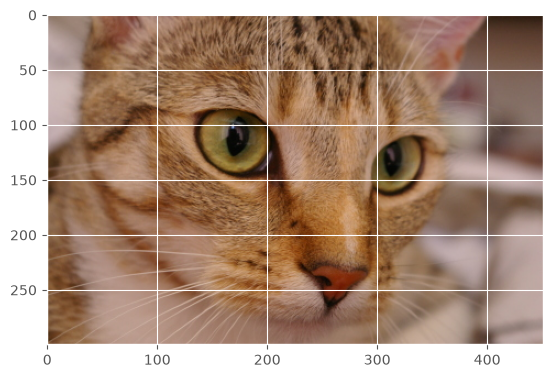

In [10]:
cat = data.chelsea()
plt.imshow(cat)

(300, 451, 3)


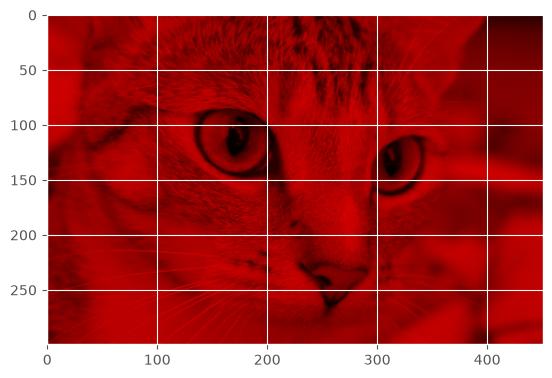

In [11]:
# It's just a ndarray!
print(cat.shape)

# The first two dimensions are position, and the third is RGB color.

# we can make the image monochrome on the red channel
red_cat = cat.copy()
red_cat[:, :, 1] = 0
red_cat[:, :, 2] = 0
plt.imshow(red_cat)

(300, 450, 3)


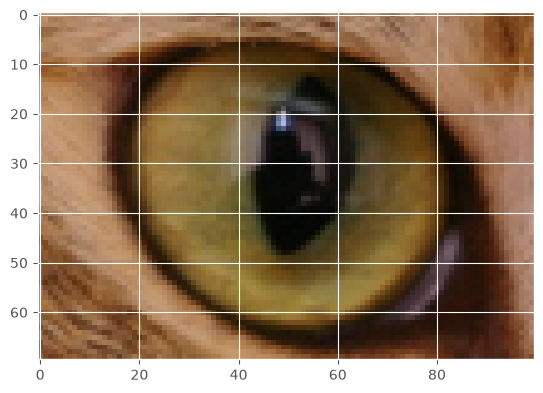

In [12]:
# Cropping the image
remove_last_column = cat[:, :-1, :]
print(remove_last_column.shape)

focus_on_eye = cat[80:150, 120:220, :]
plt.imshow(focus_on_eye)

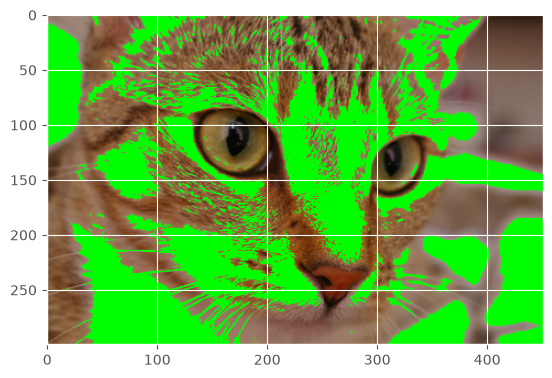

In [13]:
# Color Modification (read from each pixel the red channel and if the red intensity is > 160, then make that pixel green
copycat = cat.copy()
copycat[copycat[:, :, 0] > 160] = [0, 255, 0]
plt.imshow(copycat)

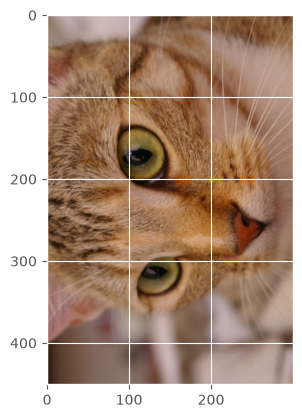

In [14]:
# Transpose the image (make the transposition only for the first 2 matrices (position) and leave the third one as it is (color))
plt.imshow(cat.transpose((1, 0, 2)))

### Understanding Strides

In [15]:
my_array = np.arange(12).reshape(4, 3)

print("Datatype: ", my_array.dtype) # 4 bytes
print("Strides: ", my_array.strides) # What does this mean?

Datatype:  int64
Strides:  (24, 8)


In [16]:
# my_array is stored as a contiguous block of memory. 
print("Stored more like this: ", my_array.flatten())

# How we see it
print("\nHow we see it:\n", my_array)

Stored more like this:  [ 0  1  2  3  4  5  6  7  8  9 10 11]

How we see it:
 [[ 0  1  2]
 [ 3  4  5]
 [ 6  7  8]
 [ 9 10 11]]


In [17]:
# Transposing is (ridiculously) cheap
transpose = my_array.transpose()
print(transpose.strides)

# Slicing is (ridiculously) cheap
every_other_element = my_array[::2, ::2]
print(every_other_element.strides)

(8, 24)
(48, 16)
